<a href="https://colab.research.google.com/github/Devyani006/Machine-Learning-CIE-2-activity/blob/main/ReelScope_(ML_Activity_1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Machine Learning CIE  – Activity 1
## ReelScope: TikTok Video Analytics

**Objective:** To inspect, clean, analyze and prepare
TikTok video analytics data for future machine learning.

**Name** : Devyani Dhokrat.  **Roll No** : AD3146

In [ ]:
import pandas as pd
import numpy as np

# Dataset source
url = "https://huggingface.co/datasets/datahiveai/Tiktok-Videos/resolve/main/train.csv"


df = pd.read_csv(
    url,
    dtype={
        "url": "string",
        "video_id": "string",
        "author_id": "string",
        "author_unique_id": "string"
    }
)

print("Dataset shape:", df.shape)


Dataset shape: (2060, 14)


In [ ]:
display(df.head())

,url,digg_count,play_count,share_count,repost_count,collect_count,comment_count,video_id,author_id,duration,description,create_time,author_unique_id,location_created
0,https://www.tiktok.com/@zachking/video/1001169...,857800.0,1700000.0,476.0,0.0,335.0,1508.0,100116967235219456,68616495085350913,0.0,When it's trash night at my house #dailylife,1464212460,zachking,NaN
1,https://www.tiktok.com/@zachking/video/1164457...,1100000.0,2000000.0,637.0,0.0,467.0,1988.0,116445712837398528,68616495085350913,15.0,#MamaSaid to always be a gentleman,1468105536,zachking,NaN
2,https://www.tiktok.com/@zachking/video/1165721...,1000000.0,2100000.0,790.0,0.0,455.0,2683.0,116572195421646848,68616495085350913,11.0,I've got #NoMoney ...oh wait,1468135692,zachking,NaN
3,https://www.tiktok.com/@zachking/video/1185885...,1200000.0,2600000.0,3157.0,0.0,1616.0,7378.0,118588521136766976,68616495085350913,13.0,#PikachuBeatDrop I found a pikachu,1468616422,zachking,NaN
4,https://www.tiktok.com/@zachking/video/1214467...,806700.0,2300000.0,831.0,0.0,513.0,2287.0,121446730818019328,68616495085350913,15.0,My heart will go on forever #badflutesong,1469297872,zachking,NaN


In [ ]:
display(df.tail())


,url,digg_count,play_count,share_count,repost_count,collect_count,comment_count,video_id,author_id,duration,description,create_time,author_unique_id,location_created
2055,https://www.tiktok.com/@zachking/video/8334847...,1100000.0,2000000.0,329.0,0.0,296.0,1879.0,83348477484662785,68616495085350913,15.0,A magical #StopMotion,1460214540,zachking,NaN
2056,https://www.tiktok.com/@zachking/video/8564247...,1100000.0,1900000.0,1110.0,0.0,586.0,2222.0,85642476228616192,68616495085350913,13.0,Practicing a little magic trick #muserMagicShow,1460761472,zachking,NaN
2057,https://www.tiktok.com/@zachking/video/8605376...,746300.0,1700000.0,315.0,0.0,225.0,1358.0,86053768974213120,68616495085350913,7.0,Do something simple and fun with a loved one. ...,1460859532,zachking,NaN
2058,https://www.tiktok.com/@zachking/video/8728339...,965200.0,2100000.0,986.0,0.0,512.0,2326.0,87283398238429184,68616495085350913,7.0,Rolling out of bed in the morning #DailyLife,1461152698,zachking,NaN
2059,https://www.tiktok.com/@zachking/video/9238474...,980300.0,1800000.0,667.0,0.0,391.0,1749.0,92384740334284800,68616495085350913,10.0,Behind the scenes of when I #WhenIMakeAVideo,1462368953,zachking,NaN


In [ ]:
print("Column names:")
print(df.columns.tolist())


Column names:
['url', 'digg_count', 'play_count', 'share_count', 'repost_count', 'collect_count', 'comment_count', 'video_id', 'author_id', 'duration', 'description', 'create_time', 'author_unique_id', 'location_created']


In [ ]:
print("\nData types:")
print(df.dtypes)



Data types:
url                 string[python]
digg_count                 float64
play_count                 float64
share_count                float64
repost_count               float64
collect_count              float64
comment_count              float64
video_id            string[python]
author_id           string[python]
duration                   float64
description                 object
create_time                  int64
author_unique_id    string[python]
location_created            object
dtype: object


In [ ]:
print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 2060
Number of columns: 14


In [ ]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))


Numerical Columns:
['digg_count', 'play_count', 'share_count', 'repost_count', 'collect_count', 'comment_count', 'duration', 'create_time']

Categorical Columns:
['url', 'video_id', 'author_id', 'description', 'author_unique_id', 'location_created']

Number of numerical columns: 8
Number of categorical columns: 6


In [ ]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
digg_count,2057.0,1.568597e+06,2.320108e+06,19900.0,3.601000e+05,8.329000e+05,1.800000e+06,2.540000e+07
play_count,2057.0,2.172212e+07,4.384796e+07,327000.0,5.900000e+06,1.260000e+07,2.430000e+07,1.100000e+09
share_count,2057.0,3.316600e+04,2.581332e+05,299.0,3.494000e+03,8.414000e+03,2.010000e+04,1.020000e+07
repost_count,2057.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
collect_count,2057.0,5.716715e+04,1.014760e+05,203.0,1.143000e+04,2.630600e+04,6.268600e+04,1.360762e+06
comment_count,2057.0,2.473437e+04,1.201009e+05,272.0,3.257000e+03,7.498000e+03,1.890000e+04,4.800000e+06
duration,2057.0,4.704229e+01,3.883194e+01,0.0,1.500000e+01,4.000000e+01,7.000000e+01,6.220000e+02
create_time,2060.0,1.669754e+09,8.742307e+07,0.0,1.643607e+09,1.692332e+09,1.718379e+09,1.740645e+09


In [ ]:
print("Creator frequency:")
display(df['author_unique_id'].value_counts())

print("\nLocation frequency:")
display(df['location_created'].value_counts(dropna=False))

print("\nRepost count distribution:")
display(df['repost_count'].value_counts().head(10))


Creator frequency:


,count
author_unique_id,
williesalim,1008
zachking,481
mrbeast,347
addisonre,221



Location frequency:


,count
location_created,
ID,998
US,989
NaN,61
SG,4
JP,3
QA,2
DE,1
AE,1
IS,1



Repost count distribution:


,count
repost_count,
0.0,2057


In [ ]:
# Investigating views as a possible future target, cause other columns have something missing.
print("Views statistics:")
print(df['play_count'].describe())

print("\nNumber of unique view counts:")
print(df['play_count'].nunique())

print("\nTop 10 videos by views:")
display(
    df.nlargest(10, 'play_count')[
        ['author_unique_id', 'description', 'play_count',
         'digg_count', 'share_count', 'comment_count']
    ]
)


Views statistics:
count    2.057000e+03
mean     2.172212e+07
std      4.384796e+07
min      3.270000e+05
25%      5.900000e+06
50%      1.260000e+07
75%      2.430000e+07
max      1.100000e+09
Name: play_count, dtype: float64

Number of unique view counts:
598

Top 10 videos by views:


,author_unique_id,description,play_count,digg_count,share_count,comment_count
126,zachking,This is the best hiding spot ever #hideandseek...,1.100000e+09,9600000.0,60300.0,17100.0
102,zachking,Do you see the glass as half full or half empt...,9.674000e+08,13300000.0,493600.0,70500.0
99,zachking,⚠️ Caution wet paint. Who watched until the end??,6.607000e+08,11300000.0,244200.0,68100.0
268,addisonre,i had to do it before my mom did.... goodnight...,3.313000e+08,25400000.0,1700000.0,414900.0
1978,mrbeast,TikTok check your inbox 👀 @TikTok,3.063000e+08,16700000.0,1300000.0,439600.0
1274,zachking,Zen Gardening,2.863000e+08,9800000.0,77000.0,51600.0
726,zachking,“Time is an illusion” - Albert Einstein | I t...,2.413000e+08,9700000.0,55800.0,21200.0
872,zachking,This is Puzzling 🧩,2.322000e+08,12600000.0,152100.0,22800.0
385,zachking,Never walk on someone’s #chalk #art,2.180000e+08,19300000.0,108700.0,58900.0
271,addisonre,#duet with @sherinicolee I- SHE WENT HARDER TH...,2.142000e+08,17200000.0,145400.0,161100.0


In [ ]:
# Missing values
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage
url,0,0.000000
digg_count,3,0.145631
play_count,3,0.145631
share_count,3,0.145631
repost_count,3,0.145631
collect_count,3,0.145631
comment_count,3,0.145631
video_id,0,0.000000
author_id,3,0.145631
duration,3,0.145631


In [ ]:
# Unique values and suspicious columns
print("Unique values in each column:")
display(df.nunique(dropna=False))

print("\nRepost count unique values:")
print(df['repost_count'].unique())

print("\nCreate time minimum and zero count:")
print("Minimum:", df['create_time'].min())
print("Zero timestamps:", (df['create_time'] == 0).sum())

print("\nDuration zero count:")
print((df['duration'] == 0).sum())

print("\nDuplicate rows:", df.duplicated().sum())

Unique values in each column:


,0
url,2060
digg_count,1213
play_count,599
share_count,1509
repost_count,2
collect_count,2029
comment_count,1560
video_id,2060
author_id,5
duration,163



Repost count unique values:
[ 0. nan]

Create time minimum and zero count:
Minimum: 0
Zero timestamps: 3

Duration zero count:
9

Duplicate rows: 0


In [ ]:
# Zero timestamps
print("Records with zero create_time:")
display(df[df['create_time'] == 0])

# Missing play_count
print("\nRecords with missing play_count:")
display(df[df['play_count'].isnull()])


print("\nIndex of zero timestamps:")
print(df[df['create_time'] == 0].index.tolist())

print("\nIndex of missing play_count:")
print(df[df['play_count'].isnull()].index.tolist())

Records with zero create_time:


,url,digg_count,play_count,share_count,repost_count,collect_count,comment_count,video_id,author_id,duration,description,create_time,author_unique_id,location_created
437,https://www.tiktok.com/@addisonre/video/701800...,NaN,NaN,NaN,NaN,NaN,NaN,7018002764059970822,<NA>,NaN,NaN,0,<NA>,NaN
588,https://www.tiktok.com/@addisonre/video/710918...,NaN,NaN,NaN,NaN,NaN,NaN,7109182019652881707,<NA>,NaN,NaN,0,<NA>,NaN
1533,https://www.tiktok.com/@addisonre/video/738116...,NaN,NaN,NaN,NaN,NaN,NaN,7381163348903316782,<NA>,NaN,NaN,0,<NA>,NaN



Records with missing play_count:


,url,digg_count,play_count,share_count,repost_count,collect_count,comment_count,video_id,author_id,duration,description,create_time,author_unique_id,location_created
437,https://www.tiktok.com/@addisonre/video/701800...,NaN,NaN,NaN,NaN,NaN,NaN,7018002764059970822,<NA>,NaN,NaN,0,<NA>,NaN
588,https://www.tiktok.com/@addisonre/video/710918...,NaN,NaN,NaN,NaN,NaN,NaN,7109182019652881707,<NA>,NaN,NaN,0,<NA>,NaN
1533,https://www.tiktok.com/@addisonre/video/738116...,NaN,NaN,NaN,NaN,NaN,NaN,7381163348903316782,<NA>,NaN,NaN,0,<NA>,NaN



Index of zero timestamps:
[437, 588, 1533]

Index of missing play_count:
[437, 588, 1533]


In [ ]:
# Kinda suspicious, so inspecting videos with zero duration
print("Records with zero duration:")

display(df[df['duration'] == 0][
    ['video_id', 'author_unique_id', 'description',
     'duration', 'play_count', 'create_time']
])

Records with zero duration:


,video_id,author_unique_id,description,duration,play_count,create_time
0,100116967235219456,zachking,When it's trash night at my house #dailylife,0.0,1700000.0,1464212460
9,141928945859395584,zachking,When a vending machine tries to steal my snack...,0.0,2900000.0,1474181213
13,184945471767912448,zachking,Online shopping with my dog. #DressUpYourPetDay,0.0,5000000.0,1484437152
33,6539263440530183183,zachking,Hope you have a blessed #Easter. 🐣 What is you...,0.0,5700000.0,1522540953
409,69946994479226880,zachking,Good #morning,0.0,1400000.0,1457019377
900,72309044245299200,zachking,I always knew they were real #wigglepet #dance...,0.0,2000000.0,1457582534
1364,7329724974384696581,williesalim,Kepiting termahal di dunia,0.0,30100000.0,1706584588
2048,75385247101554688,zachking,#BedtimeMusic,0.0,1400000.0,1458315958
2051,78154214731849728,zachking,Who else loves #Easter candy?,0.0,1800000.0,1458976131


In [ ]:
# Creating an untouched backup, just as instructed and in case I mess up
df_original = df.copy(deep=True)

# Removing records with missing play_count cause these are the same three records with zero create_time.
df_clean = df_original.dropna(subset=['play_count']).copy()

# Cleaning the missing categorical values.
df_clean['description'] = df_clean['description'].fillna(
    'No description available'
)

df_clean['location_created'] = df_clean['location_created'].fillna(
    'Unknown'
)

# Removing the constant repost_count column cause all available values are zero, so it provides no useful variation.
df_clean = df_clean.drop(columns=['repost_count'])

# Verifing the cleaning, obviously.
print("Original shape:", df_original.shape)
print("Prepared shape:", df_clean.shape)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:", df_clean.duplicated().sum())

print("\nZero-duration records retained:",
      (df_clean['duration'] == 0).sum())

print("\nOriginal dataset unchanged:",
      df_original.shape == df.shape)

Original shape: (2060, 14)
Prepared shape: (2057, 13)

Missing values after cleaning:


,0
url,0
digg_count,0
play_count,0
share_count,0
collect_count,0
comment_count,0
video_id,0
author_id,0
duration,0
description,0



Duplicate rows after cleaning: 0

Zero-duration records retained: 9

Original dataset unchanged: True


The Decision of mine :
1. Three records (indices 437, 588 and 1533) were removed because their engagement metrics and several other important fields were missing.



2. Missing descriptions were replaced with "No description available".



3. Missing locations were replaced with "Unknown".



4. repost_count was removed because all its non-missing values were zero, making it a constant column.



5. Nine zero-duration records were retained because they contained other useful information. Their duration values will be treated as a data-quality limitation.



6. The original dataset was preserved before cleaning.




In [ ]:
# Check individual column data types
print("Column Data Types:\n")
print(df_clean.dtypes)

# Detailed dataset information
print("\nDataset Information:\n")
df_clean.info()

# Display first five records
print("\nFirst Five Records:\n")
display(df_clean.head())

Column Data Types:

url                 string[python]
digg_count                 float64
play_count                 float64
share_count                float64
collect_count              float64
comment_count              float64
video_id            string[python]
author_id           string[python]
duration                   float64
description                 object
create_time                  int64
author_unique_id    string[python]
location_created            object
dtype: object

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
Index: 2057 entries, 0 to 2059
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   url               2057 non-null   string 
 1   digg_count        2057 non-null   float64
 2   play_count        2057 non-null   float64
 3   share_count       2057 non-null   float64
 4   collect_count     2057 non-null   float64
 5   comment_count     2057 non-null   float64
 6   video

,url,digg_count,play_count,share_count,collect_count,comment_count,video_id,author_id,duration,description,create_time,author_unique_id,location_created
0,https://www.tiktok.com/@zachking/video/1001169...,857800.0,1700000.0,476.0,335.0,1508.0,100116967235219456,68616495085350913,0.0,When it's trash night at my house #dailylife,1464212460,zachking,Unknown
1,https://www.tiktok.com/@zachking/video/1164457...,1100000.0,2000000.0,637.0,467.0,1988.0,116445712837398528,68616495085350913,15.0,#MamaSaid to always be a gentleman,1468105536,zachking,Unknown
2,https://www.tiktok.com/@zachking/video/1165721...,1000000.0,2100000.0,790.0,455.0,2683.0,116572195421646848,68616495085350913,11.0,I've got #NoMoney ...oh wait,1468135692,zachking,Unknown
3,https://www.tiktok.com/@zachking/video/1185885...,1200000.0,2600000.0,3157.0,1616.0,7378.0,118588521136766976,68616495085350913,13.0,#PikachuBeatDrop I found a pikachu,1468616422,zachking,Unknown
4,https://www.tiktok.com/@zachking/video/1214467...,806700.0,2300000.0,831.0,513.0,2287.0,121446730818019328,68616495085350913,15.0,My heart will go on forever #badflutesong,1469297872,zachking,Unknown


### Step 1: Basic Exploratory Data Analysis (EDA)
We will look at simple descriptive statistics and two basic charts to understand the general distribution of our data.

,digg_count,play_count,share_count,collect_count,comment_count,duration,create_time,create_datetime,year,month,day,day_of_week,hour,desc_char_len,desc_word_count
count,2.057000e+03,2.057000e+03,2.057000e+03,2.057000e+03,2.057000e+03,2057.000000,2.057000e+03,2057,2057.000000,2057.000000,2057.000000,2057.000000,2057.000000,2057.000000,2057.000000
mean,1.568597e+06,2.172212e+07,3.316600e+04,5.716715e+04,2.473437e+04,47.042295,1.672189e+09,2022-12-28 00:55:57.920758528,2022.433155,7.188624,15.660185,2.860476,12.638308,45.184249,7.220710
min,1.990000e+04,3.270000e+05,2.990000e+02,2.030000e+02,2.720000e+02,0.000000,1.456702e+09,2016-02-28 23:33:55,2016.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,3.601000e+05,5.900000e+06,3.494000e+03,1.143000e+04,3.257000e+03,15.000000,1.643946e+09,2022-02-04 03:38:22,2022.000000,4.000000,8.000000,1.000000,9.000000,22.000000,3.000000
50%,8.329000e+05,1.260000e+07,8.414000e+03,2.630600e+04,7.498000e+03,40.000000,1.692398e+09,2023-08-18 22:30:13,2023.000000,8.000000,15.000000,3.000000,14.000000,32.000000,5.000000
75%,1.800000e+06,2.430000e+07,2.010000e+04,6.268600e+04,1.890000e+04,70.000000,1.718425e+09,2024-06-15 04:15:05,2024.000000,10.000000,23.000000,4.000000,17.000000,55.000000,9.000000
max,2.540000e+07,1.100000e+09,1.020000e+07,1.360762e+06,4.800000e+06,622.000000,1.740645e+09,2025-02-27 08:22:12,2025.000000,12.000000,31.000000,6.000000,23.000000,773.000000,163.000000
std,2.320108e+06,4.384796e+07,2.581332e+05,1.014760e+05,1.201009e+05,38.831944,5.983148e+07,NaN,1.865238,3.465703,8.907749,1.888548,5.787284,43.520676,7.601127


/tmp/ipykernel_1613/572427673.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='location_created', order=df_clean['location_created'].value_counts().index, palette='Set2', ax=axes[1])


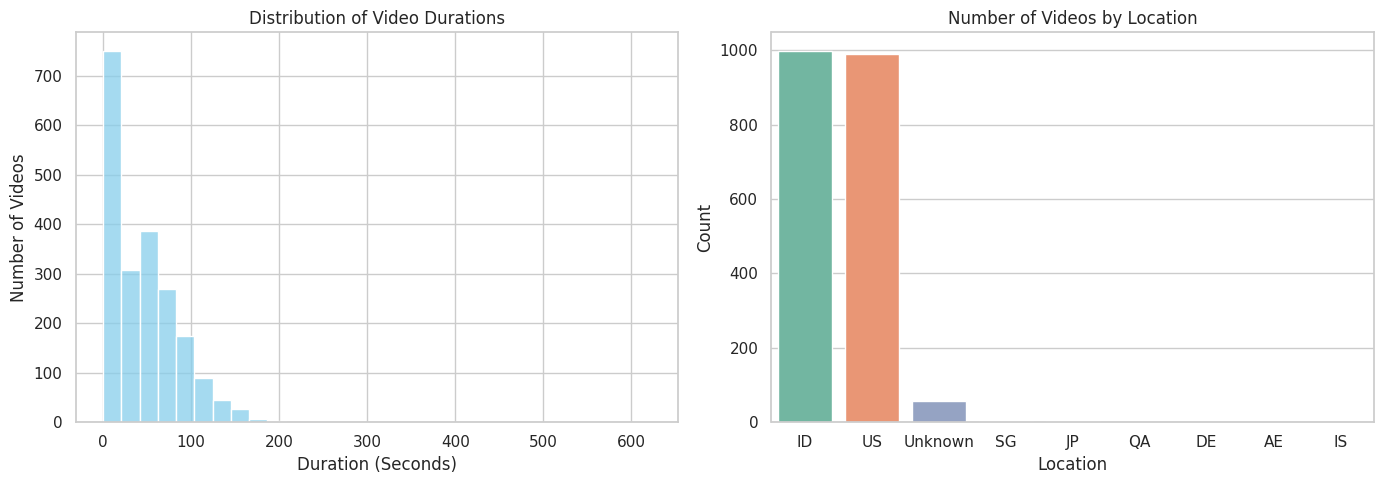

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

display(df_clean.describe())


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Histogram of Video Durations
sns.histplot(df_clean['duration'], bins=30, color='skyblue', ax=axes[0])
axes[0].set_title('Distribution of Video Durations')
axes[0].set_xlabel('Duration (Seconds)')
axes[0].set_ylabel('Number of Videos')

# Chart 2: Bar Chart of Locations
sns.countplot(data=df_clean, x='location_created', order=df_clean['location_created'].value_counts().index, palette='Set2', ax=axes[1])
axes[1].set_title('Number of Videos by Location')
axes[1].set_xlabel('Location')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


#Chart 1 (Duration):
The majority of tiktok videos in this dataset are short, mostly clustering around the 15-60 second mark, which basically means that each video must be around 60 second or less, not more then that.

#Chart 2 (Loaction):
Most of the videos were created in the 'ID' i.e Indonesia and 'US' i.e United States regions, now this shows that a strong geographic concentration must be another reason for virality, according to me.

### Step 2: Encoding and Scaling
Machine Learning models need numbers to calculate patterns, so :
1. **Encode** categorical text (like location) into 1s and 0s.
2. **Scale** large numerical ranges (like millions of views) down to a standard 0 to 1 range.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# 1. Encoding: Convert categorical text (location) into numerical format (1s and 0s)
df_prepared = pd.get_dummies(df_clean, columns=['location_created'], drop_first=True)

# 2. Scaling: Bring numerical columns to a standard range (0 to 1)
scaler = MinMaxScaler()
numerical_features_to_scale = ['play_count', 'digg_count', 'share_count', 'comment_count', 'duration']

df_prepared[numerical_features_to_scale] = scaler.fit_transform(df_prepared[numerical_features_to_scale])

print("Final Prepared Dataset after Encoding and Scaling :")
display(df_prepared.head())

--- Final Prepared Dataset after Encoding and Scaling ---


,url,digg_count,play_count,share_count,collect_count,comment_count,video_id,author_id,duration,description,...,desc_char_len,desc_word_count,location_created_DE,location_created_ID,location_created_IS,location_created_JP,location_created_QA,location_created_SG,location_created_US,location_created_Unknown
0,https://www.tiktok.com/@zachking/video/1001169...,0.033014,0.001249,0.000017,335.0,0.000258,100116967235219456,68616495085350913,0.000000,When it's trash night at my house #dailylife,...,44,8,False,False,False,False,False,False,False,True
1,https://www.tiktok.com/@zachking/video/1164457...,0.042557,0.001521,0.000033,467.0,0.000358,116445712837398528,68616495085350913,0.024116,#MamaSaid to always be a gentleman,...,35,6,False,False,False,False,False,False,False,True
2,https://www.tiktok.com/@zachking/video/1165721...,0.038617,0.001612,0.000048,455.0,0.000502,116572195421646848,68616495085350913,0.017685,I've got #NoMoney ...oh wait,...,28,5,False,False,False,False,False,False,False,True
3,https://www.tiktok.com/@zachking/video/1185885...,0.046497,0.002067,0.000280,1616.0,0.001481,118588521136766976,68616495085350913,0.020900,#PikachuBeatDrop I found a pikachu,...,34,5,False,False,False,False,False,False,False,True
4,https://www.tiktok.com/@zachking/video/1214467...,0.031001,0.001794,0.000052,513.0,0.000420,121446730818019328,68616495085350913,0.024116,My heart will go on forever #badflutesong,...,41,7,False,False,False,False,False,False,False,True


#Conclusion & Summary of Dataset Preparation:

I selected a TikTok video analytics dataset with various engagement metrics and categorical features.

Cleaning: Handled missing values by dropping a negligible amount of null records (3 rows) and imputing missing categorical fields with 'Unknown'. Also dropped constant columns like repost_count.

EDA: Basic visualizations showed that viewership and engagement metrics are heavily right-skewed, and a majority of the dataset videos are under 60 seconds long.

Encoding & Scaling: Applied One-Hot Encoding to the categorical location data so it can be processed mathematically. Also applied Min-Max Scaling to the heavy numerical features (like views and likes) to normalize their ranges between 0 and 1.

Result: The dataset is now clean, free of null values, mathematically scaled, and structurally ready for a downstream Machine Learning pipeline.